In [30]:
import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch Version: 2.14.1+cu130
CUDA Available: True
GPU: Tesla T4


In [31]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Libraries imported successfully!")
print("Using device:", device)

Libraries imported successfully!
Using device: cuda


In [32]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [33]:
import os

base_path = "/content/microscopy_data/small_images"

noisy_path = os.path.join(base_path, "noisy")
gt_path = os.path.join(base_path, "gt")

print("Noisy folder exists:", os.path.exists(noisy_path))
print("GT folder exists:", os.path.exists(gt_path))

if os.path.exists(noisy_path):
    print("Noisy images:", len(os.listdir(noisy_path)))

if os.path.exists(gt_path):
    print("Ground truth images:", len(os.listdir(gt_path)))

Noisy folder exists: True
GT folder exists: True
Noisy images: 2457
Ground truth images: 2457


In [34]:
import os

print("MyDrive contents:")
print(os.listdir("/content/drive/MyDrive"))

print("\nCurrent runtime contents:")
print(os.listdir("/content"))

MyDrive contents:
['Colab Notebooks', 'student.hithaldia.org ExistStudent ClassTestAdmit.aspx', 'Classroom', 'Copy of DSA patterns Cheat Sheet.gsheet', 'Screenshot 2026-01-03 221941.png', 'Google AI Studio', 'Copy of Proposal_Template_WoC_5.docx', 'woc', 'Screenshot 2026-01-14 213401.png', 'Screenshot 2026-01-14 213456.png', 'Screenshot 2026-01-14 214138.png', 'Screenshot 2026-01-14 214327.png', 'Screenshot 2026-01-14 214837.png', 'Screenshot 2026-02-01 002156.png', 'Screenshot 2026-02-01 002617.png', 'myvideo', 'DBMS_Full_Notes.gdoc', 'Chinmaya_Sa_Resume.gdoc', 'resumesuyash (1).pdf', 'resumesuyash.pdf', 'contributor.png', 'Odoo Hackathon Participant Document.gdoc', 'Untitled document.gdoc', 'Mandarmani', 'sih (1).docx', 'sih.docx', 'sihnomination.pdf', 'Copy of Data Science Application Development using Streamlit AD.pptx', 'Screenshot_20261031-124956_Chrome.png', 'patient-prescription.pdf', 'Microscopy-Denoising', 'Suyash_Jaiswal_Resume (2).gdoc', 'Suyash_Jaiswal_Resume (1).gdoc', 'S

In [35]:
project_path = "/content/drive/MyDrive/Microscopy-Denoising"

for root, dirs, files in os.walk(project_path):
    level = root.replace(project_path, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    print("  " * level + os.path.basename(root) + "/")

    for file in files[:5]:
        print("  " * (level + 1) + file)


Microscopy-Denoising/
  standard_unet_results.csv
  experiment_comparison_E3_E4.csv
  dncnn_results.csv
  experiment_comparison_E3_E4_E6.csv
  checkpoints/
    unet_best.pth
    unet_latest.pth
    unet_edge_best.pth
    dncnn_best.pth


In [36]:
import os

data_path = "/content/drive/MyDrive/Microscopy-Denoising/data"

print("Data folder exists:", os.path.exists(data_path))

Data folder exists: False


In [37]:
!wget -O /content/Archive.zip \
"https://zenodo.org/records/15624741/files/Archive.zip?download=1"

--2026-11-21 10:12:17--  https://zenodo.org/records/15624741/files/Archive.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.47.192, 188.185.51.60, 137.138.121.78, ...
Connecting to zenodo.org (zenodo.org)|188.185.47.192|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 290061612 (277M) [application/octet-stream]
Saving to: ‘/content/Archive.zip’

/content/Archive.zi 100%[===================>] 276.62M  4.28MB/s    in 66s     

2026-11-21 10:13:24 (4.16 MB/s) - ‘/content/Archive.zip’ saved [290061612/290061612]



In [38]:
import hashlib

file_path = "/content/Archive.zip"

md5 = hashlib.md5()

with open(file_path, "rb") as f:
    for chunk in iter(lambda: f.read(8192), b""):
        md5.update(chunk)

actual_md5 = md5.hexdigest()

print("MD5:", actual_md5)
print("Checksum valid:", actual_md5 == "6a268178418294bb86705fb925a6c532")


MD5: 6a268178418294bb86705fb925a6c532
Checksum valid: True


In [39]:
import zipfile
import os

extract_path = "/content/microscopy_data"

with zipfile.ZipFile("/content/Archive.zip", "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))

Dataset extracted successfully!
['__MACOSX', 'large_images', 'small_images']


In [40]:
import os

base_path = "/content/microscopy_data/small_images"

noisy_path = os.path.join(base_path, "noisy")
gt_path = os.path.join(base_path, "gt")

noisy_files = sorted(os.listdir(noisy_path))
gt_files = sorted(os.listdir(gt_path))

print("Noisy images:", len(noisy_files))
print("GT images:", len(gt_files))

print("Sample noisy file:", noisy_files[0])
print("Sample GT file:", gt_files[0])

print("Same filenames:", noisy_files == gt_files)

Noisy images: 2457
GT images: 2457
Sample noisy file: 1000.tif
Sample GT file: 1000.tif
Same filenames: True


In [41]:
import pandas as pd

split_base = "https://raw.githubusercontent.com/suyash-jaiswal-7/Microscopy-Denoising/main/outputs/splits"

train_df = pd.read_csv(f"{split_base}/train.csv")
val_df = pd.read_csv(f"{split_base}/validation.csv")
test_df = pd.read_csv(f"{split_base}/test.csv")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 1719
Validation: 369
Test: 369


In [42]:
NOISY_SCALE = 78.0
GT_SCALE = 2252.0

print("Noisy normalization:", NOISY_SCALE)
print("GT normalization:", GT_SCALE)

Noisy normalization: 78.0
GT normalization: 2252.0


In [43]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import os

class MicroscopyDataset(Dataset):
    def __init__(self, dataframe, noisy_path, gt_path):
        self.dataframe = dataframe
        self.noisy_path = noisy_path
        self.gt_path = gt_path

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        filename = self.dataframe.iloc[idx]["filename"]

        noisy = np.array(
            Image.open(os.path.join(self.noisy_path, filename)),
            dtype=np.float32
        ) / NOISY_SCALE

        gt = np.array(
            Image.open(os.path.join(self.gt_path, filename)),
            dtype=np.float32
        ) / GT_SCALE

        noisy = torch.from_numpy(noisy).unsqueeze(0)
        gt = torch.from_numpy(gt).unsqueeze(0)

        return noisy, gt

In [44]:
train_dataset = MicroscopyDataset(
    train_df,
    noisy_path,
    gt_path
)

noisy, gt = train_dataset[0]

print("Noisy image shape:", noisy.shape)
print("Ground Truth shape:", gt.shape)
print("Noisy dtype:", noisy.dtype)
print("GT dtype:", gt.dtype)
print("Noisy range:", noisy.min().item(), noisy.max().item())
print("GT range:", gt.min().item(), gt.max().item())

Noisy image shape: torch.Size([1, 256, 256])
Ground Truth shape: torch.Size([1, 256, 256])
Noisy dtype: torch.float32
GT dtype: torch.float32
Noisy range: 0.0 1.3205127716064453
GT range: 0.05550621822476387 1.2078152894973755


In [45]:
BATCH_SIZE = 2

val_dataset = MicroscopyDataset(val_df, noisy_path, gt_path)
test_dataset = MicroscopyDataset(test_df, noisy_path, gt_path)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 860
Validation batches: 185
Test batches: 185


In [46]:
import torch.nn as nn

class DnCNN(nn.Module):
    def __init__(self, channels=64, num_layers=17):
        super(DnCNN, self).__init__()

        layers = [
            nn.Conv2d(1, channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        ]

        for _ in range(num_layers - 2):
            layers.extend([
                nn.Conv2d(
                    channels, channels,
                    kernel_size=3, padding=1,
                    bias=False
                ),
                nn.BatchNorm2d(channels),
                nn.ReLU(inplace=True)
            ])

        layers.append(
            nn.Conv2d(channels, 1, kernel_size=3, padding=1)
        )

        self.dncnn = nn.Sequential(*layers)

    def forward(self, x):
        return self.dncnn(x)

In [47]:
model = DnCNN().to(device)

print(model)

total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nTotal trainable parameters:", total_params)

# Test with one batch
noisy_batch, gt_batch = next(iter(train_loader))
noisy_batch = noisy_batch.to(device)

predicted_noise = model(noisy_batch)

print("\nInput shape:", noisy_batch.shape)
print("Predicted noise shape:", predicted_noise.shape)

DnCNN(
  (dncnn): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): ReLU(inplace=True)
    (5): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU(inplace=True)
    (8): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (13): ReLU(inplace=True)
    

In [48]:
noisy_raw = np.array(
    Image.open(os.path.join(noisy_path, train_df.iloc[0]["filename"])),
    dtype=np.float32
)

gt_raw = np.array(
    Image.open(os.path.join(gt_path, train_df.iloc[0]["filename"])),
    dtype=np.float32
)

print("Noisy raw range:", noisy_raw.min(), noisy_raw.max())
print("GT raw range:", gt_raw.min(), gt_raw.max())

print("Noisy mean:", noisy_raw.mean())
print("GT mean:", gt_raw.mean())

print("Noisy dtype:", noisy_raw.dtype)
print("GT dtype:", gt_raw.dtype)

Noisy raw range: 0.0 103.0
GT raw range: 125.0 2720.0
Noisy mean: 13.3654175
GT mean: 393.63528
Noisy dtype: float32
GT dtype: float32


In [49]:
noisy, gt = train_dataset[0]

noise_target = noisy - gt

print("Normalized noisy mean:", noisy.mean().item())
print("Normalized GT mean:", gt.mean().item())

print("Noise target mean:", noise_target.mean().item())
print("Noise target std:", noise_target.std().item())

print("Noisy range:", noisy.min().item(), noisy.max().item())
print("GT range:", gt.min().item(), gt.max().item())
print("Noise target range:", noise_target.min().item(), noise_target.max().item())

Normalized noisy mean: 0.17135149240493774
Normalized GT mean: 0.17479361593723297
Noise target mean: -0.003442133544012904
Noise target std: 0.11701389402151108
Noisy range: 0.0 1.3205127716064453
GT range: 0.05550621822476387 1.2078152894973755
Noise target range: -0.6982055902481079 0.5686113834381104


In [50]:
import torch.nn as nn

class DnCNN(nn.Module):
    def __init__(self, channels=1, num_layers=17, features=64):
        super(DnCNN, self).__init__()

        layers = [
            nn.Conv2d(channels, features, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        ]

        for _ in range(num_layers - 2):
            layers.extend([
                nn.Conv2d(features, features, kernel_size=3, padding=1),
                nn.BatchNorm2d(features),
                nn.ReLU(inplace=True)
            ])

        layers.append(
            nn.Conv2d(features, channels, kernel_size=3, padding=1)
        )

        self.dncnn = nn.Sequential(*layers)

    def forward(self, x):
        return self.dncnn(x)

In [51]:
model_dncnn = DnCNN().to(device)

print(model_dncnn)
print("Total parameters:", sum(p.numel() for p in model_dncnn.parameters()))

DnCNN(
  (dncnn): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): ReLU(inplace=True)
    (5): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU(inplace=True)
    (8): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (13): ReLU(inplace=True)
    (14): Conv2d(64, 64, kernel_size=(3, 3), stride=

In [52]:
noisy_batch, gt_batch = next(iter(train_loader))

noisy_batch = noisy_batch.to(device)
gt_batch = gt_batch.to(device)

predicted_noise = model_dncnn(noisy_batch)

print("Input shape:", noisy_batch.shape)
print("Predicted noise shape:", predicted_noise.shape)
print("Ground truth shape:", gt_batch.shape)

denoised = noisy_batch - predicted_noise

print("Denoised output shape:", denoised.shape)

Input shape: torch.Size([2, 1, 256, 256])
Predicted noise shape: torch.Size([2, 1, 256, 256])
Ground truth shape: torch.Size([2, 1, 256, 256])
Denoised output shape: torch.Size([2, 1, 256, 256])


In [53]:
import torch.optim as optim
import os

# Loss function: compare predicted noise with actual noise
criterion = nn.MSELoss()

# Optimizer
optimizer = optim.Adam(
    model_dncnn.parameters(),
    lr=0.001
)

# Training configuration
EPOCHS = 10
best_val_loss = float("inf")

# Checkpoint directory
checkpoint_dir = "/content/drive/MyDrive/Microscopy-Denoising/checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

print("Training configuration ready!")
print("Epochs:", EPOCHS)
print("Learning rate:", 0.001)
print("Loss function: MSE")
print("Optimizer: Adam")

Training configuration ready!
Epochs: 10
Learning rate: 0.001
Loss function: MSE
Optimizer: Adam


In [58]:
from tqdm.auto import tqdm

train_losses = []
val_losses = []

for epoch in range(EPOCHS):

    # -------- TRAINING --------
    model_dncnn.train()
    running_train_loss = 0.0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]")

    for noisy_batch, gt_batch in train_bar:

        noisy_batch = noisy_batch.to(device)
        gt_batch = gt_batch.to(device)

        # Actual noise residual
        noise_target = noisy_batch - gt_batch

        # Predict noise
        predicted_noise = model_dncnn(noisy_batch)

        loss = criterion(predicted_noise, noise_target)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()
        train_bar.set_postfix(loss=f"{loss.item():.6f}")

    epoch_train_loss = running_train_loss / len(train_loader)

    # -------- VALIDATION --------
    model_dncnn.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for noisy_batch, gt_batch in val_loader:

            noisy_batch = noisy_batch.to(device)
            gt_batch = gt_batch.to(device)

            noise_target = noisy_batch - gt_batch
            predicted_noise = model_dncnn(noisy_batch)

            loss = criterion(predicted_noise, noise_target)
            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(val_loader)

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {epoch_train_loss:.6f}")
    print(f"Validation Loss: {epoch_val_loss:.6f}")

    # Save best model
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model_dncnn.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": best_val_loss
        }, os.path.join(checkpoint_dir, "dncnn_best.pth"))

        print("Best DnCNN checkpoint saved!")

print("\nTraining completed!")

Epoch 1/10 [Train]:   0%|          | 0/860 [00:00<?, ?it/s]


Epoch 1/10
Train Loss: 0.000895
Validation Loss: 0.000832
Best DnCNN checkpoint saved!


Epoch 2/10 [Train]:   0%|          | 0/860 [00:00<?, ?it/s]


Epoch 2/10
Train Loss: 0.000863
Validation Loss: 0.000865


Epoch 3/10 [Train]:   0%|          | 0/860 [00:00<?, ?it/s]


Epoch 3/10
Train Loss: 0.000804
Validation Loss: 0.000739
Best DnCNN checkpoint saved!


... (10 outputs left out)

Epoch 9/10 [Train]:   0%|          | 0/860 [00:00<?, ?it/s]


Epoch 9/10
Train Loss: 0.000679
Validation Loss: 0.000622
Best DnCNN checkpoint saved!


Epoch 10/10 [Train]:   0%|          | 0/860 [00:00<?, ?it/s]


Epoch 10/10
Train Loss: 0.000653
Validation Loss: 0.000635

Training completed!


In [59]:
checkpoint_path = os.path.join(checkpoint_dir, "dncnn_best.pth")

checkpoint = torch.load(checkpoint_path, map_location=device)

model_dncnn.load_state_dict(checkpoint["model_state_dict"])
model_dncnn.eval()

print("Best DnCNN checkpoint loaded!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["val_loss"])

Best DnCNN checkpoint loaded!
Best epoch: 9
Best validation loss: 0.0006218272287279015


In [60]:

import numpy as np
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

model_dncnn.eval()

dncnn_psnr = []
dncnn_ssim = []

with torch.no_grad():
    for noisy, gt in test_loader:
        noisy = noisy.to(device)
        gt = gt.to(device)

        # DnCNN predicts noise, not the clean image
        predicted_noise = model_dncnn(noisy)

        # Subtract predicted noise to obtain denoised image
        denoised = noisy - predicted_noise

        denoised = denoised.cpu().numpy()
        gt = gt.cpu().numpy()

        for i in range(len(denoised)):
            pred_img = denoised[i, 0]
            gt_img = gt[i, 0]

            psnr = peak_signal_noise_ratio(
                gt_img, pred_img, data_range=1.0
            )

            ssim = structural_similarity(
                gt_img, pred_img, data_range=1.0
            )

            dncnn_psnr.append(psnr)
            dncnn_ssim.append(ssim)

print("DnCNN Test Images:", len(dncnn_psnr))
print("DnCNN Average PSNR:", np.mean(dncnn_psnr))
print("DnCNN Average SSIM:", np.mean(dncnn_ssim))


DnCNN Test Images: 369
DnCNN Average PSNR: 32.4976439612899
DnCNN Average SSIM: 0.9241470956614755


In [61]:
import pandas as pd
import os

results = pd.DataFrame([{
    "Experiment": "E6 - DnCNN",
    "PSNR": np.mean(dncnn_psnr),
    "SSIM": np.mean(dncnn_ssim)
}])

results_path = "/content/drive/MyDrive/Microscopy-Denoising/dncnn_results.csv"

results.to_csv(results_path, index=False)

print(results)
print("Saved:", results_path)

   Experiment       PSNR      SSIM
0  E6 - DnCNN  32.497644  0.924147
Saved: /content/drive/MyDrive/Microscopy-Denoising/dncnn_results.csv


In [62]:
import pandas as pd

results_path = "/content/drive/MyDrive/Microscopy-Denoising/dncnn_results.csv"
comparison_path = "/content/drive/MyDrive/Microscopy-Denoising/experiment_comparison_E3_E4_E6.csv"

print("DnCNN Results:")
display(pd.read_csv(results_path).head())

print("Experiment Comparison:")
display(pd.read_csv(comparison_path))

DnCNN Results:


,Experiment,PSNR,SSIM
0,E6 - DnCNN,32.497644,0.924147


Experiment Comparison:


,Experiment,PSNR,SSIM
0,E3 - Standard U-Net,33.5645,0.94884
1,E4 - U-Net + Edge Loss,33.1809,0.94486
2,E6 - DnCNN,32.4851,0.93027


In [63]:
import pandas as pd
import os

base_path = "/content/drive/MyDrive/Microscopy-Denoising"

# Update individual DnCNN results
results_path = os.path.join(base_path, "dncnn_results.csv")

results = pd.DataFrame([{
    "Experiment": "E5 - DnCNN",
    "PSNR": np.mean(dncnn_psnr),
    "SSIM": np.mean(dncnn_ssim)
}])

results.to_csv(results_path, index=False)

# Update consolidated comparison
comparison_path = os.path.join(
    base_path, "experiment_comparison_E3_E4_E5.csv"
)

comparison = pd.DataFrame([
    {"Experiment": "E3 - Standard U-Net", "PSNR": 33.5645, "SSIM": 0.94884},
    {"Experiment": "E4 - U-Net + Edge Loss", "PSNR": 33.1809, "SSIM": 0.94486},
    {"Experiment": "E5 - DnCNN", "PSNR": np.mean(dncnn_psnr), "SSIM": np.mean(dncnn_ssim)}
])

comparison.to_csv(comparison_path, index=False)

print("Updated Results:")
display(results)

print("Final Experiment Comparison:")
display(comparison)

Updated Results:


,Experiment,PSNR,SSIM
0,E5 - DnCNN,32.497644,0.924147


Final Experiment Comparison:


,Experiment,PSNR,SSIM
0,E3 - Standard U-Net,33.564500,0.948840
1,E4 - U-Net + Edge Loss,33.180900,0.944860
2,E5 - DnCNN,32.497644,0.924147


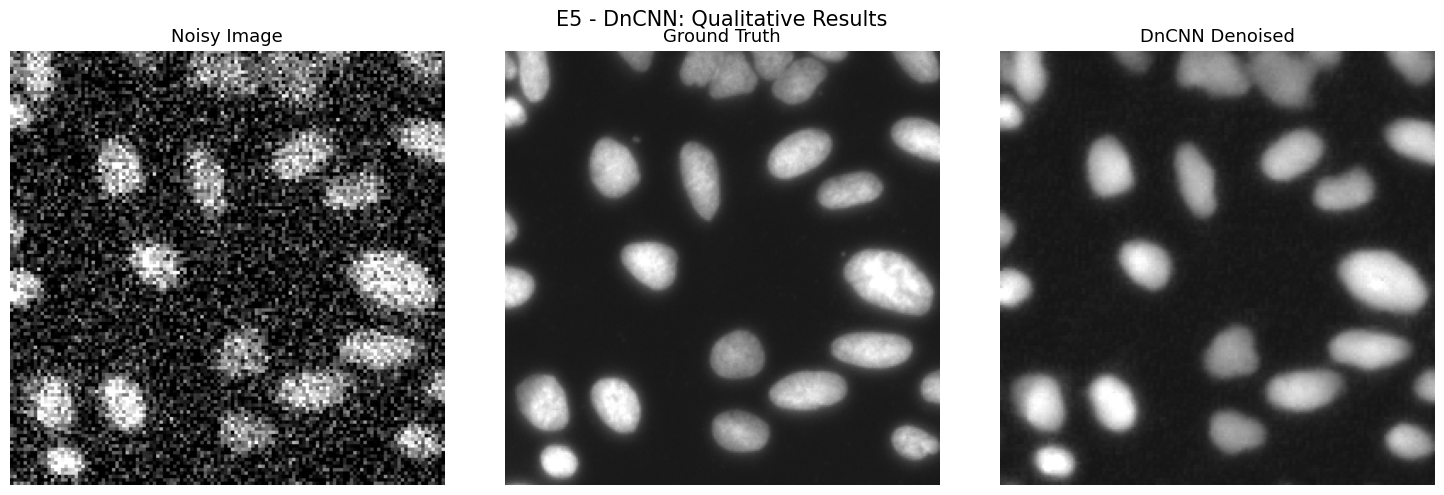

In [64]:
import matplotlib.pyplot as plt
import numpy as np
import torch

model_dncnn.eval()

# Get one batch from test dataset
noisy, gt = next(iter(test_loader))

noisy = noisy.to(device)
gt = gt.to(device)

# Generate denoised images
with torch.no_grad():
    predicted_noise = model_dncnn(noisy)
    denoised = noisy - predicted_noise

# Select first image
noisy_img = noisy[0, 0].cpu().numpy()
gt_img = gt[0, 0].cpu().numpy()
denoised_img = denoised[0, 0].cpu().numpy()

# Common display range for fair visual comparison
all_pixels = np.concatenate([
    noisy_img.ravel(),
    gt_img.ravel(),
    denoised_img.ravel()
])

vmin, vmax = np.percentile(all_pixels, [1, 99])

# Plot comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [
    (noisy_img, "Noisy Image"),
    (gt_img, "Ground Truth"),
    (denoised_img, "DnCNN Denoised")
]

for ax, (img, title) in zip(axes, images):
    ax.imshow(img, cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=13)
    ax.axis("off")

plt.suptitle("E5 - DnCNN: Qualitative Results", fontsize=15)
plt.tight_layout()
plt.show()

## Conclusion

The DnCNN model was trained using residual learning to predict and remove noise from microscopy images. The best checkpoint was obtained at epoch 9 based on validation loss.

On the test set of 369 images, the model achieved an average PSNR of 32.4976 dB and SSIM of 0.9241.

The qualitative results demonstrate effective noise reduction while retaining the overall nuclear structures. However, some degree of smoothing is visible in the denoised output.

Compared with the Standard U-Net and U-Net with Edge Loss experiments, DnCNN achieved lower PSNR and SSIM under the current experimental setup.